# IngresoJusto: flujo de Machine Learning con auditoría ética

Notebook del mini-proyecto. Recorre cada etapa del flujo básico de ML con el código de `src/`:
problema → datos → preparación → partición → selección de modelo → entrenamiento → umbral →
evaluación → interpretabilidad → equidad.

**Pregunta:** ¿se puede estimar, con datos censales, si una persona gana más de 50 000 USD al año
para preseleccionar ofertas de crédito, y es justo hacerlo?

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

from src import config
from src.data import load_raw, clean, split, profile
from src.train import compare_candidates, fit_logistic, choose_threshold, fit_baseline
from src.evaluate import classification_metrics, predict_with_threshold
from src.fairness import group_table, disparities
pd.set_option("display.max_columns", 20)

## 1. Datos

Dataset **Adult** (UCI Machine Learning Repository, censo de EE. UU. de 1994; Becker y Kohavi, 1996).
Cada fila es una persona; el objetivo es `income`: `>50K` o `<=50K`.

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
X, y = clean(raw)
print(f"Duplicados eliminados: {len(raw) - len(X)}")
perfil = profile(X, y)
pd.Series({k: v for k, v in perfil.items() if not isinstance(v, dict)})

Duplicados eliminados: 52


filas            48790.0000
columnas            14.0000
tasa_positiva        0.2394
dtype: float64

In [4]:
pd.DataFrame({"faltantes": perfil["faltantes"]})

,faltantes
workclass,2795
occupation,2805
native_country,856


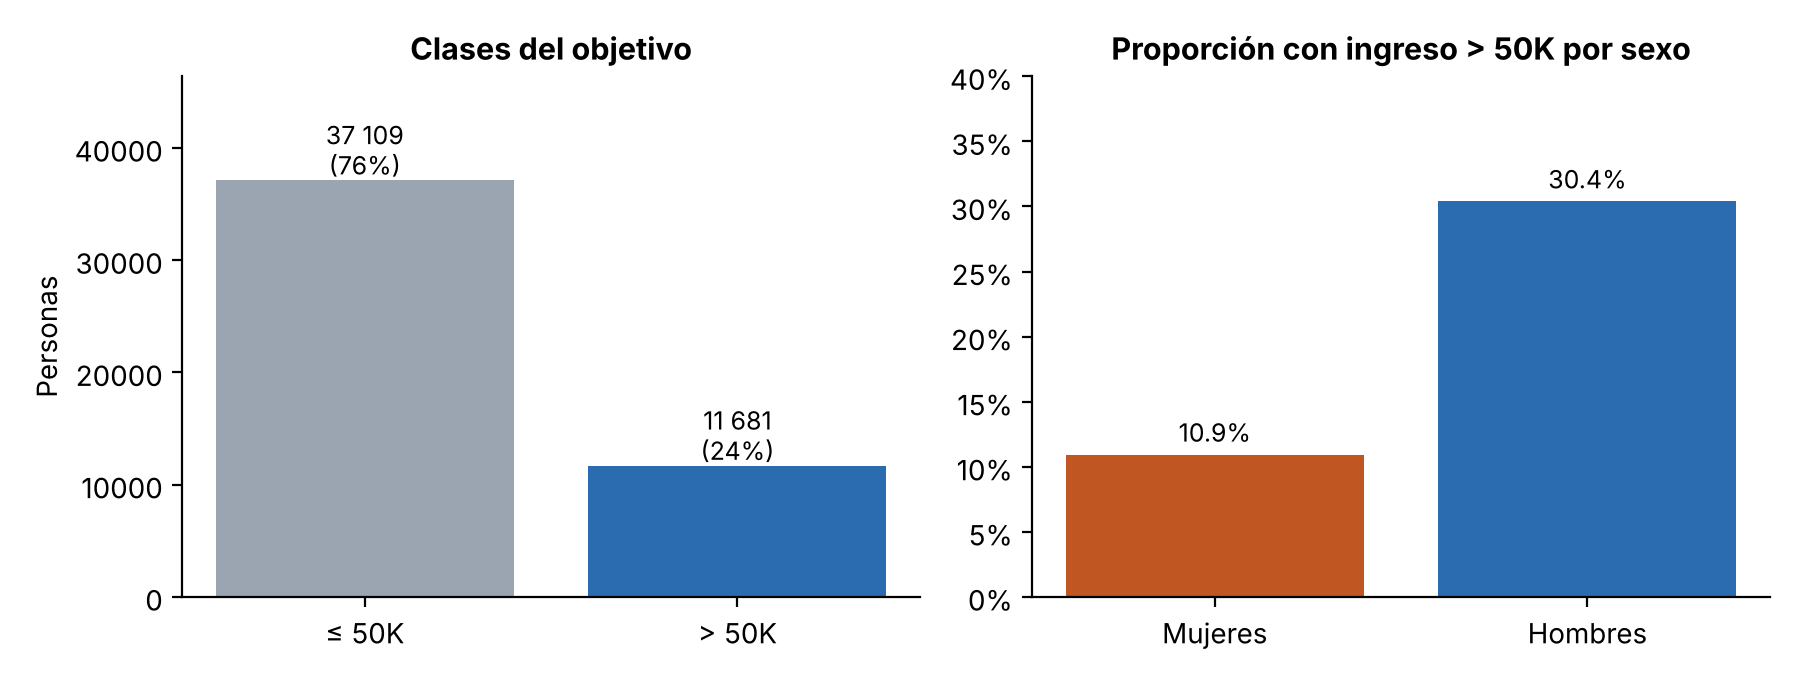

,tasa_positiva,proporcion
Female,0.1094,0.3315
Male,0.3039,0.6685


In [5]:
display(Image(filename=str(config.FIGURES / "01_clases.png")))
pd.DataFrame({"tasa_positiva": perfil["tasa_positiva_por_sexo"], "proporcion": perfil["proporcion_por_sexo"]})

El objetivo está desbalanceado (24 % positivos) y la tasa de ingreso alto de los hombres
casi triplica la de las mujeres. Ese sesgo histórico del dataset es el punto de partida del análisis ético.

## 2. Preparación y partición

- Variables del modelo: numéricas (edad, años de educación, horas por semana), asimétricas
  (ganancia y pérdida de capital, con `log1p`) y categóricas (tipo de empleo, estado civil, ocupación, relación familiar).
- **Excluidas:** `sex`, `race` y `native_country` (atributos sensibles, solo para auditar), `fnlwgt` y `education`.
- Imputación, escalado y one-hot viven dentro de un `Pipeline`: se ajustan solo con entrenamiento.
- Partición estratificada 70 / 15 / 15 con semilla 42.

In [6]:
pd.Series(config.EXCLUDED, name="motivo de exclusión")

fnlwgt            peso muestral del censo, no describe a la persona
education         redundante con education_num (misma informació...
native_country    atributo sensible (origen nacional) y 90 % de ...
sex               atributo protegido: solo se usa para auditar e...
race              atributo protegido: solo se usa para auditar e...
Name: motivo de exclusión, dtype: str

In [7]:
p = split(X, y)
(X_tr, y_tr), (X_va, y_va), (X_te, y_te) = p["train"], p["val"], p["test"]
pd.DataFrame({k: {"filas": len(v[1]), "tasa_positiva": round(v[1].mean(), 4)} for k, v in p.items()}).T

,filas,tasa_positiva
train,34152.0,0.2394
val,7319.0,0.2394
test,7319.0,0.2394


## 3. Selección del modelo

Validación cruzada estratificada de 5 pliegues, solo sobre entrenamiento. La línea base predice siempre
la clase mayoritaria.

In [8]:
comparacion = compare_candidates(X_tr, y_tr)
comparacion

,modelo,accuracy,f1,roc_auc,f1_desv
0,Línea base (clase mayoritaria),0.7606,0.0000,0.5000,0.0000
1,Regresión logística,0.8445,0.6430,0.8993,0.0106
2,Árbol de decisión (profundidad 8),0.8552,0.6484,0.9026,0.0095
3,KNN (k = 25),0.8465,0.6635,0.8981,0.0101


Los tres modelos quedan a menos de 0,02 de F1 entre sí. Se elige la **regresión logística**
por transparencia (coeficientes interpretables), probabilidades útiles para fijar el umbral y porque,
a diferencia de KNN, no necesita guardar los datos personales de entrenamiento para predecir (ADR-002).

## 4. Entrenamiento y elección del umbral

C elegido: 0.1 · umbral que maximiza F1 en validación: 0.26


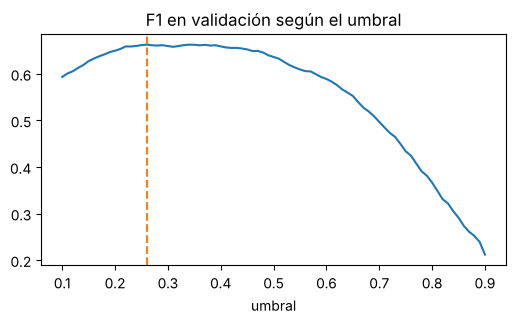

In [9]:
modelo, C = fit_logistic(X_tr, y_tr)
umbral, curva = choose_threshold(modelo, X_va, y_va)
print(f"C elegido: {C} · umbral que maximiza F1 en validación: {umbral}")
ax = curva.plot(x="umbral", y="f1", legend=False, figsize=(6, 3), title="F1 en validación según el umbral")
ax.axvline(umbral, ls="--", color="tab:orange");

## 5. Evaluación en prueba (una sola vez)

In [10]:
y_pred, y_score = predict_with_threshold(modelo, X_te, umbral, config.FEATURES)
base = fit_baseline(X_tr, y_tr)
base_pred = base.predict(X_te[config.FEATURES])
tabla = pd.DataFrame({
    "Regresión logística": classification_metrics(y_te, y_pred, y_score),
    "Regresión logística (umbral 0,5)": classification_metrics(y_te, (y_score >= 0.5).astype(int), y_score),
    "Línea base": classification_metrics(y_te, base_pred, base.predict_proba(X_te[config.FEATURES])[:, 1]),
})
tabla

,Regresión logística,"Regresión logística (umbral 0,5)",Línea base
accuracy,0.8071,0.8489,0.7606
precision,0.5676,0.7234,0.0000
recall,0.8151,0.5970,0.0000
f1,0.6692,0.6542,0.0000
roc_auc,0.9017,0.9017,0.5000
vp,1428.0000,1046.0000,0.0000
fp,1088.0000,400.0000,0.0000
vn,4479.0000,5167.0000,5567.0000
fn,324.0000,706.0000,1752.0000


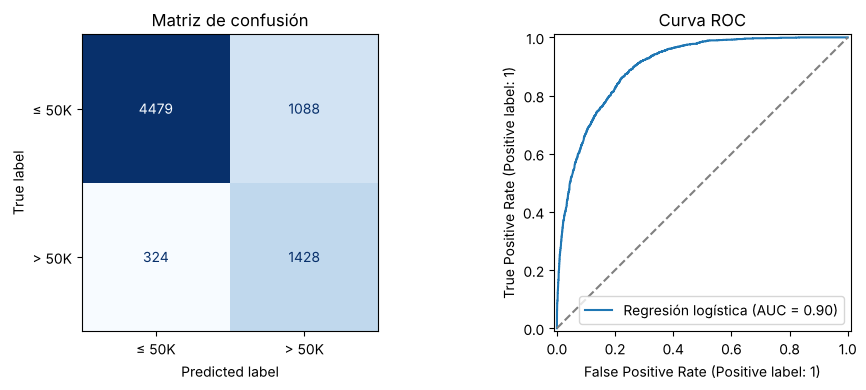

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, display_labels=["≤ 50K", "> 50K"], cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Matriz de confusión")
RocCurveDisplay.from_predictions(y_te, y_score, ax=ax[1], name="Regresión logística")
ax[1].plot([0, 1], [0, 1], "--", color="gray"); ax[1].set_title("Curva ROC")
plt.tight_layout()

- **VP:** personas con ingreso alto que el modelo detecta.
- **FP:** personas con ingreso bajo que el modelo marca como alto (riesgo de ofrecer crédito sin capacidad de pago).
- **VN:** personas con ingreso bajo correctamente descartadas.
- **FN:** personas con ingreso alto que el modelo pasa por alto (pierden la oferta aunque califican).

## 6. Interpretabilidad

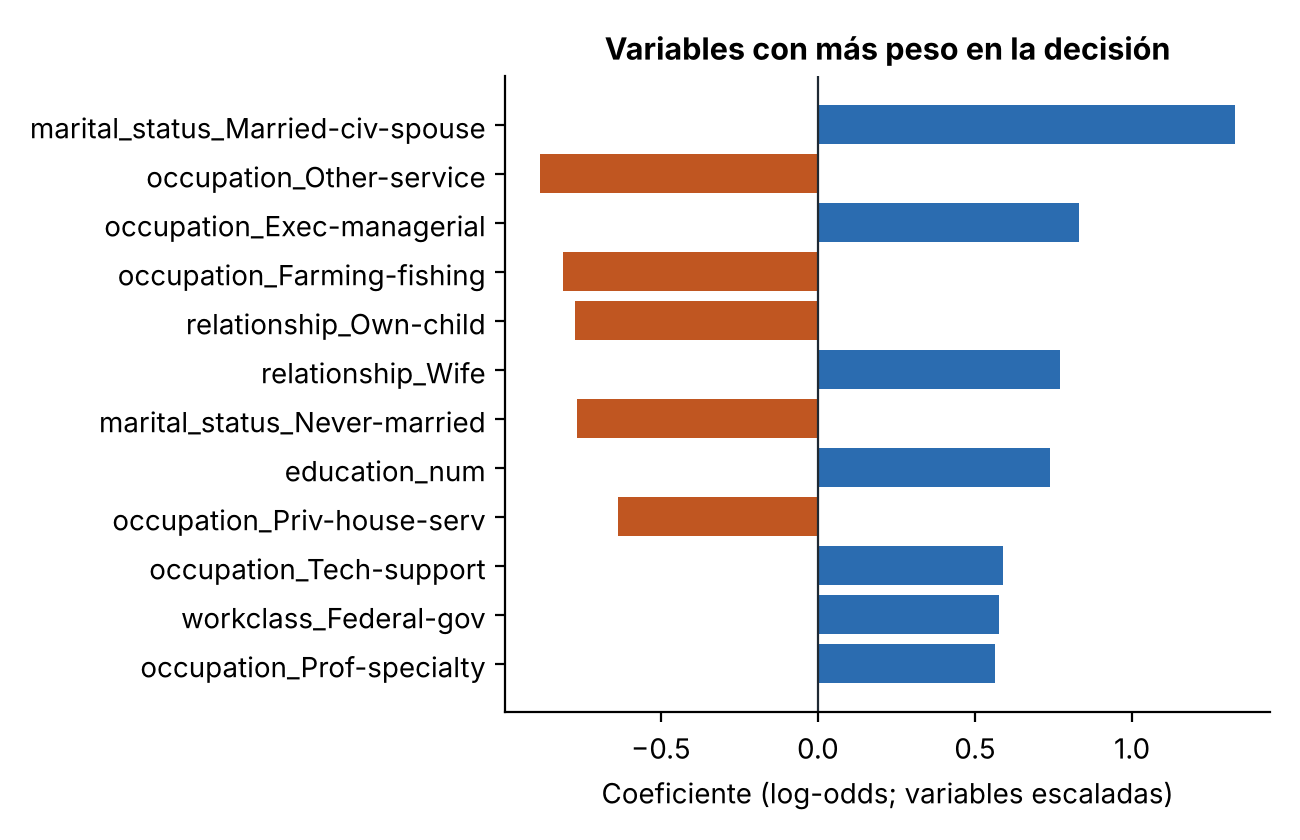

In [12]:
display(Image(filename=str(config.FIGURES / "05_coeficientes.png")))

`relationship_Wife` empuja la predicción hacia arriba: el modelo no ve el sexo, pero `relationship`
lo revela casi por completo (Husband = hombre en el 99,99 % de los casos). Es una variable **proxy**.

## 7. Auditoría de equidad

In [13]:
t_sexo = group_table(X_te["sex"], y_te, y_pred)
t_raza = group_table(X_te["race"], y_te, y_pred)
display(t_sexo, t_raza)
pd.DataFrame({"sexo": disparities(t_sexo), "raza": disparities(t_raza)})

,grupo,n,tasa_base,tasa_seleccion,precision,tpr,fpr,muestra_suficiente
0,Male,4823,0.3048,0.4485,0.5700,0.8388,0.2774,True
1,Female,2496,0.1130,0.1414,0.5524,0.6915,0.0714,True


,grupo,n,tasa_base,tasa_seleccion,precision,tpr,fpr,muestra_suficiente
0,White,6264,0.2548,0.3675,0.5743,0.8283,0.2099,True
1,Black,689,0.1248,0.1597,0.4818,0.6163,0.0945,True
2,Asian-Pac-Islander,232,0.2284,0.3362,0.5385,0.7925,0.2011,True
3,Amer-Indian-Eskimo,71,0.1127,0.2254,0.3750,0.7500,0.1587,False
4,Other,63,0.1429,0.1587,0.5000,0.5556,0.0926,False


,sexo,raza
diferencia_paridad_demografica,0.3071,0.2078
razon_impacto_dispar,0.3153,0.4346
diferencia_igualdad_oportunidades,0.1473,0.212
diferencia_probabilidades_igualadas,0.206,0.212
grupos_evaluados,"[Male, Female]","[White, Black, Asian-Pac-Islander]"


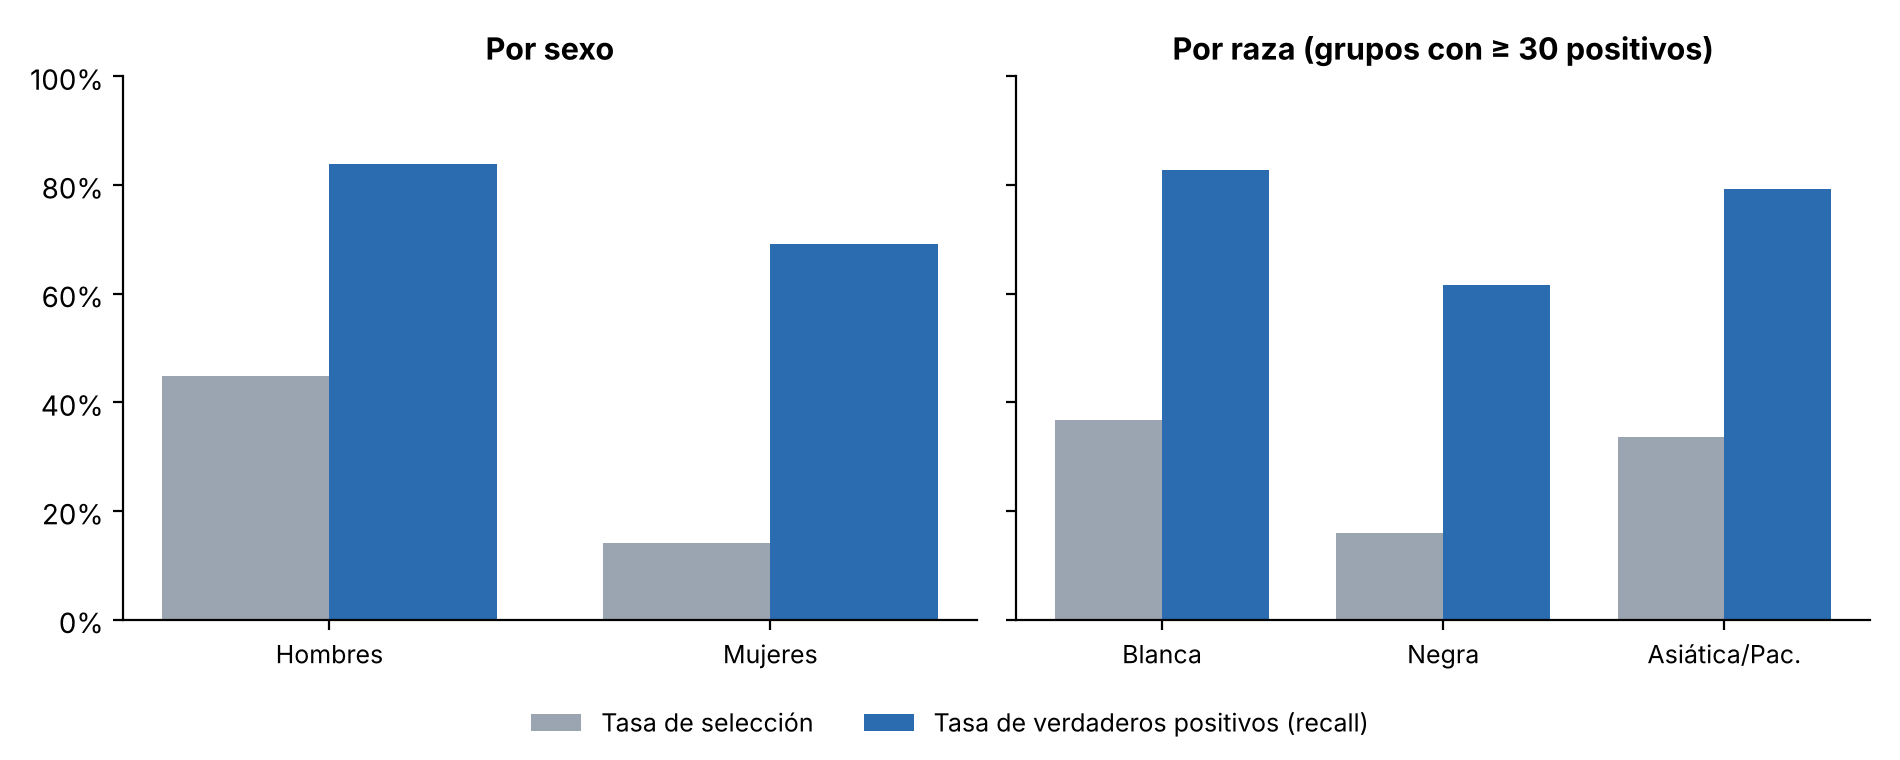

In [14]:
display(Image(filename=str(config.FIGURES / "06_equidad.png")))

### Experimento: ¿qué pasa si el modelo sí usa sexo y raza?

In [15]:
feats_s = config.FEATURES + config.SENSITIVE
modelo_s, _ = fit_logistic(X_tr, y_tr, features=feats_s, categorical=config.CATEGORICAL + config.SENSITIVE)
umbral_s, _ = choose_threshold(modelo_s, X_va, y_va, features=feats_s)
pred_s, score_s = predict_with_threshold(modelo_s, X_te, umbral_s, feats_s)
pd.DataFrame({
    "sin sexo ni raza": {**classification_metrics(y_te, y_pred, y_score), **disparities(t_sexo)},
    "con sexo y raza": {**classification_metrics(y_te, pred_s, score_s), **disparities(group_table(X_te["sex"], y_te, pred_s))},
}).drop(index=["vp", "fp", "vn", "fn", "grupos_evaluados"])

,sin sexo ni raza,con sexo y raza
accuracy,0.8071,0.8403
precision,0.5676,0.6519
recall,0.8151,0.714
f1,0.6692,0.6816
roc_auc,0.9017,0.9024
diferencia_paridad_demografica,0.3071,0.2599
razon_impacto_dispar,0.3153,0.2591
diferencia_igualdad_oportunidades,0.1473,0.2297
diferencia_probabilidades_igualadas,0.206,0.2297


Excluir los atributos protegidos **reduce** la brecha, pero no la elimina: las variables proxy
mantienen parte del sesgo. Por eso el modelo no cumple los criterios éticos AC4 y AC5 y solo se acepta
como apoyo a una decisión humana, con revisión de los casos rechazados.

## 8. Conclusión

El modelo cumple los criterios técnicos (F1 ≥ 0,65; ROC-AUC ≥ 0,85; supera ampliamente la línea base),
pero no los de equidad. El análisis completo, las recomendaciones y las decisiones de arquitectura están
en el `README.md` y en `docs/Informe_IngresoJusto.pdf`.

In [16]:
acept = json.loads((config.REPORTS / "metrics.json").read_text())["aceptacion"]
pd.DataFrame(acept).T

,umbral,valor,cumple
AC1_f1,0.65,0.6692,True
AC2_roc_auc,0.85,0.9017,True
AC3_supera_linea_base,0.3,0.6692,True
AC4_igualdad_oportunidades_sexo,0.1,0.1473,False
AC5_impacto_dispar_sexo,0.8,0.3153,False
